#### Question-6 Linear and non-linear embedding with `sklearn.datasets.make_swiss_roll` dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll, load_wine
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

(1500, 3)


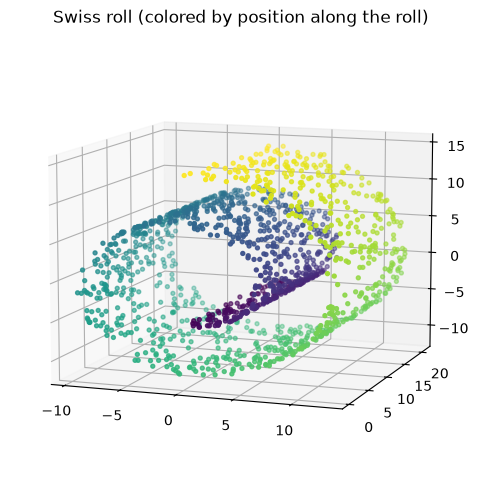

In [2]:
# X: (1500, 3) points in 3D; t: each point's position along the roll (used only for coloring)
X, t = make_swiss_roll(n_samples=1500, noise=0.05, random_state=0)
print(X.shape)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=t, cmap='viridis', s=8)
ax.set_title('Swiss roll (colored by position along the roll)')
ax.view_init(elev=10, azim=-70)
plt.show()

### PCA vs. t-SNE on the Swiss roll (part c)

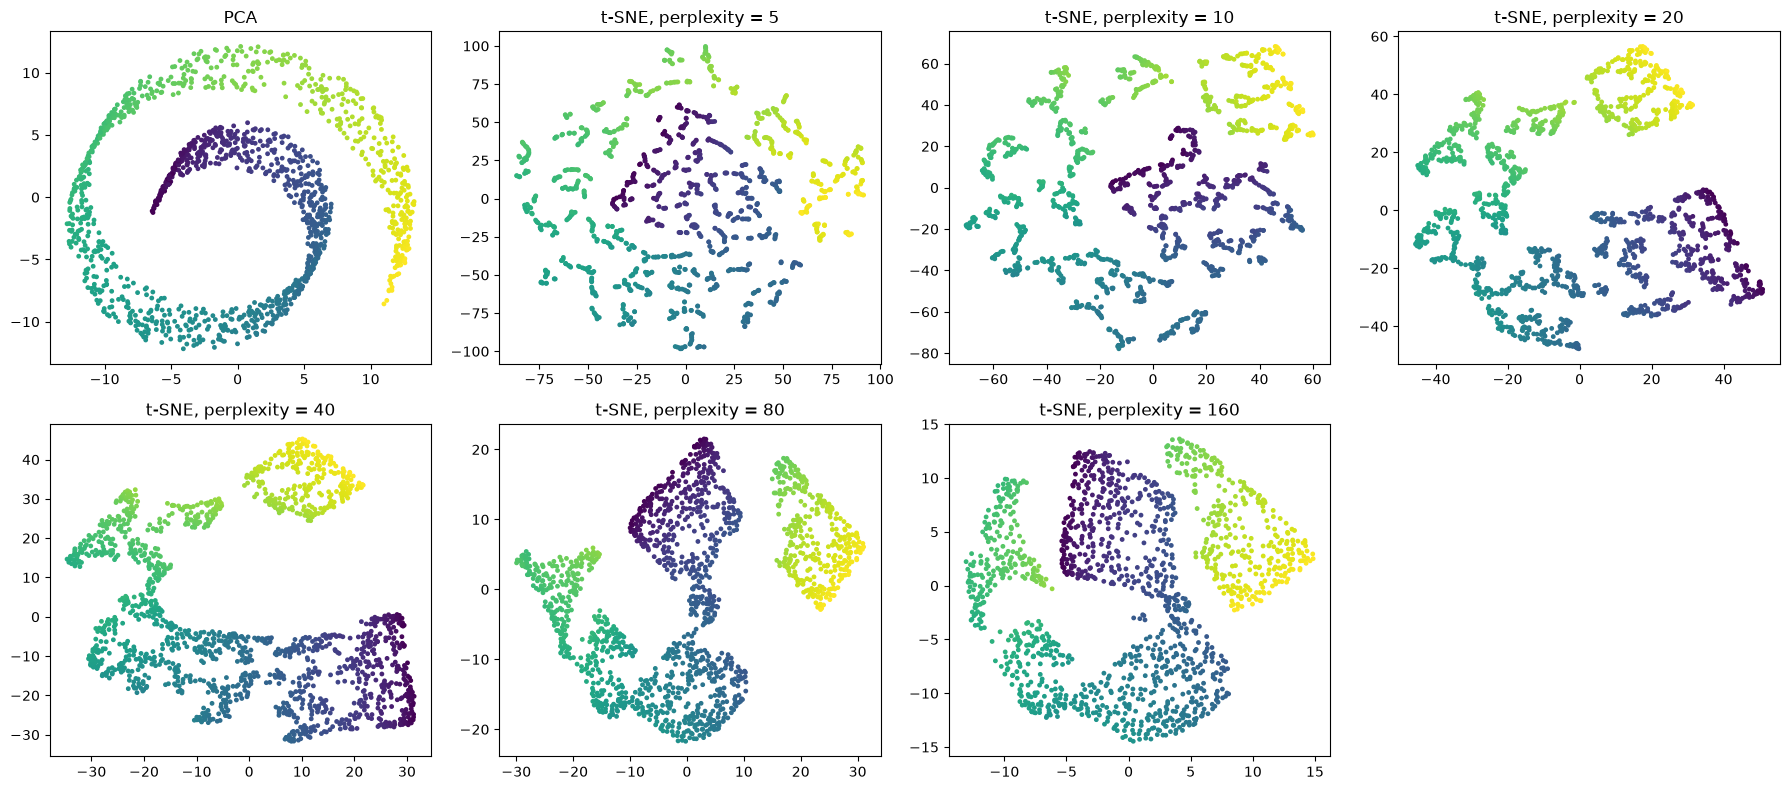

In [3]:
# PCA
X_pca = PCA(n_components=2).fit_transform(X)

# t-SNE at several perplexities
perplexities = [5, 10, 20, 40, 80, 160]
tsne_results = {p: TSNE(n_components=2, perplexity=p, init='pca', random_state=0).fit_transform(X)
                for p in perplexities}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=t, cmap='viridis', s=6); axes[0].set_title('PCA')
for ax, p in zip(axes[1:], perplexities):
    ax.scatter(tsne_results[p][:, 0], tsne_results[p][:, 1], c=t, cmap='viridis', s=6)
    ax.set_title(f't-SNE, perplexity = {p}')
axes[-1].axis('off')
plt.tight_layout(); plt.show()

### Wine dataset

PCA explained variance: [0.362 0.192]


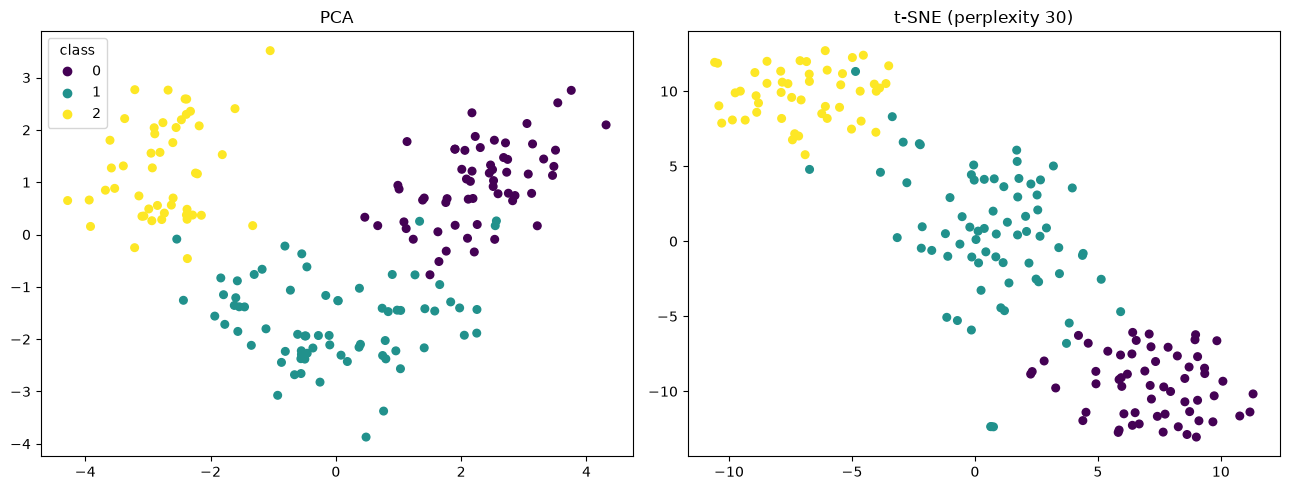

In [4]:
wine = load_wine()
Xw, yw = wine.data, wine.target                     # 178 samples, 13 features, 3 classes
Xw_s = StandardScaler().fit_transform(Xw)           

pca_w = PCA(n_components=2).fit(Xw_s)
Xw_pca = pca_w.transform(Xw_s)
print("PCA explained variance:", pca_w.explained_variance_ratio_.round(3))

Xw_tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=0).fit_transform(Xw_s)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, E, title in zip(ax, [Xw_pca, Xw_tsne], ['PCA', 't-SNE (perplexity 30)']):
    sc = a.scatter(E[:, 0], E[:, 1], c=yw, cmap='viridis', s=30)
    a.set_title(title)
ax[0].legend(*sc.legend_elements(), title='class')
plt.tight_layout(); plt.show()

- PCA on the Swiss roll returned the spiral cross-section, because the two highest-variance directions are the spiral directions. So it could not unroll the manifold, and adjacent turns lie close together in the projection. - t-SNE preserved local neighborhoods and recovered the color ordering along the roll, but the result depended strongly on perplexity: values of 5 and 10 fragmented the sheet into many small pieces, 20 to 40 gave a connected, ordered ribbon, and 80 to 160 gave compact blobs in which the sheet curled and its two ends moved close together. 
- On the wine data (standardized, 13 features), PCA’s first two components captured 55.4% of the variance and separated class 2 clearly, with partial overlap between classes 0 and 1. t-SNE (perplexity 30) separated all three classes more cleanly, with a few stray points. This indicates that wine is almost linearly separable. So a linear method already well, whereas non-linear embedding with the Swiss roll’s curved structure.